# 🧩 Grouping & Joining: groupby, pivot_table, merge

**Zero Grad · Data Analysis course · Pandas**

> 📖 **The lesson (in Arabic), with diagrams and interactive widgets:** [zero-grad.com/courses/da/grouping](https://zero-grad.com/courses/da/grouping/)
>
> 🗂️ **The data:** [NileCart Sales on Kaggle](https://www.kaggle.com/datasets/a7madmostafa/nilecart-sales)

This is the solved notebook of the *Grouping & joining* lesson.
Most business questions are "per something": revenue **per** category, orders **per** customer, sales **per** month.
And the answer is rarely in one table: the order has the `customer_id`, the customer's name is in another file.

| # | Part | The question |
|---|---|---|
| 1 | `groupby` | One number per group |
| 2 | `agg` | Several numbers per group, with names |
| 3 | `transform` | The group's number, back on every row |
| 4 | `pivot_table` and `crosstab` | A two-way table |
| 5 | `concat` | Stack tables |
| 6 | `merge` | Join tables on a key |
| 7 | Join types | inner, left, right, outer |
| 8 | Merge traps | Keys that don't match, keys that repeat |

---
# 0️⃣ Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4)
pd.options.display.float_format = "{:,.2f}".format

# On Kaggle the data lives under /kaggle/input, locally in the repo's data/ folder
on_kaggle = sorted(Path("/kaggle/input").glob("**/sales.csv"))
DATA = on_kaggle[0].parent if on_kaggle else Path("../../data")

sales = pd.read_csv(DATA / "sales.csv", parse_dates=["order_date"])
done = sales[sales["status"] == "completed"]
print(len(done), "completed order lines")

1074 completed order lines


---
# 1️⃣ `groupby`: one number per group

`groupby` does three things: **split** the rows into groups, **apply** a calculation to each group, **combine** the answers into one table.

In [2]:
done.groupby("category")["revenue"].sum()

category
Accessories    1,364,333.45
Electronics   15,747,455.00
Furniture      2,260,647.05
Stationery        39,886.50
Name: revenue, dtype: float64

Read it as: *group the rows by `category`, take the `revenue` column, and `sum` it in each group.*
The result is a Series whose index is the groups.

The same, done by hand, to see the three steps:

In [3]:
answers = {}
for cat, rows in done.groupby("category"):          # split: one small DataFrame per category
    answers[cat] = rows["revenue"].sum()             # apply
pd.Series(answers)                                   # combine

Accessories    1,364,333.45
Electronics   15,747,455.00
Furniture      2,260,647.05
Stationery        39,886.50
dtype: float64

## 1.1 Any calculation, any column

In [4]:
print(done.groupby("region")["revenue"].sum().sort_values(ascending=False))

region
Greater Cairo        9,912,413.20
Alexandria & Coast   4,062,245.75
Delta                1,999,446.75
Upper Egypt          1,823,958.55
Canal                1,612,633.25
Unknown                  1,624.50
Name: revenue, dtype: float64


In [5]:
done.groupby("product_name")["quantity"].sum().sort_values(ascending=False).head(5)

product_name
Mouse      728.00
Notebook   703.00
Keyboard   575.00
Backpack   472.00
Lamp       341.00
Name: quantity, dtype: float64

In [6]:
done.groupby("segment").size()          # size(): how many rows per group

segment
Consumer          553
Corporate         393
Small Business    127
Unknown             1
dtype: int64

## 1.2 Several group columns

In [7]:
by_year_cat = done.groupby([done["order_date"].dt.year, "category"])["revenue"].sum()
by_year_cat

order_date  category   
2024        Accessories     572,289.90
            Electronics   7,925,890.00
            Furniture     1,223,678.80
            Stationery       17,662.20
2025        Accessories     792,043.55
            Electronics   7,821,565.00
            Furniture     1,036,968.25
            Stationery       22,224.30
Name: revenue, dtype: float64

Two group columns give a two-level index (a `MultiIndex`). `unstack()` turns the inner level into columns:

In [8]:
by_year_cat.unstack()

category,Accessories,Electronics,Furniture,Stationery
order_date,,,,
2024,"572,289.90","7,925,890.00","1,223,678.80","17,662.20"
2025,"792,043.55","7,821,565.00","1,036,968.25","22,224.30"


## 1.3 `as_index=False`: the groups as a column

In [9]:
done.groupby("category", as_index=False)["revenue"].sum()

,category,revenue
0,Accessories,"1,364,333.45"
1,Electronics,"15,747,455.00"
2,Furniture,"2,260,647.05"
3,Stationery,"39,886.50"


---
# 2️⃣ `agg`: several numbers per group

The previous lesson's rule: never a group statistic without its `count`.

In [10]:
done.groupby("category")["revenue"].agg(["count", "sum", "mean", "median"]).sort_values("sum", ascending=False)

,count,sum,mean,median
category,,,,
Electronics,269,"15,747,455.00","58,540.72","41,800.00"
Furniture,184,"2,260,647.05","12,286.13","6,982.50"
Accessories,453,"1,364,333.45","3,011.77","2,360.00"
Stationery,168,"39,886.50",237.42,221.70


## 2.1 Named aggregation: one column per result, any input column

In [11]:
per_customer = (done.groupby(["customer_id", "name"])
                    .agg(orders=("order_id", "nunique"),
                         units=("quantity", "sum"),
                         revenue=("revenue", "sum"),
                         first=("order_date", "min"),
                         last=("order_date", "max"))
                    .sort_values("revenue", ascending=False))
print(len(per_customer), "customers with a completed order")
per_customer.head()

155 customers with a completed order


,,orders,units,revenue,first,last
customer_id,name,,,,,
50,Dina Hassan,24,156.00,"1,141,956.10",2024-01-09,2025-12-28
34,Yasmin Saleh,11,55.00,"771,654.40",2024-08-10,2025-12-13
95,Reem Fawzy,19,142.00,"704,899.50",2024-01-14,2025-12-10
132,Yasmin Mostafa,22,144.00,"672,268.60",2024-01-01,2025-12-07
172,Mona Gamal,37,213.00,"597,714.60",2024-02-10,2025-12-29


`new_name=("column", "function")`: the result gets a clear name, and each one can use a different column.
The best customer bought for more than a million EGP in 24 order lines.

In [12]:
top10 = per_customer["revenue"].head(10).sum() / per_customer["revenue"].sum()
print(f"the top 10 customers bring {top10:.0%} of the revenue")

the top 10 customers bring 33% of the revenue


---
# 3️⃣ `transform`: the group's number, back on every row

`agg` gives **one row per group**. `transform` gives **one value per original row**: the group's answer, repeated on each of its rows.
That lets you compare a row with its group.

In [13]:
d = done.copy()
d["category_total"] = d.groupby("category")["revenue"].transform("sum")
d["share_of_category"] = d["revenue"] / d["category_total"]
d[["order_id", "category", "revenue", "category_total", "share_of_category"]].head()

,order_id,category,revenue,category_total,share_of_category
1,10001,Electronics,"259,920.00","15,747,455.00",0.02
2,10004,Stationery,570.00,"39,886.50",0.01
4,10005,Accessories,"4,560.00","1,364,333.45",0.00
5,10006,Electronics,"31,350.00","15,747,455.00",0.00
8,10011,Accessories,"1,624.50","1,364,333.45",0.00


In [14]:
print(len(d), "rows, the same as done")
d.loc[d["share_of_category"].idxmax(), ["name", "product_name", "revenue", "share_of_category"]]

1074 rows, the same as done


name                 Reem Fawzy
product_name               Desk
revenue               55,575.00
share_of_category          0.02
Name: 321, dtype: object

Another common one: each line against the median of its category.

In [15]:
d["vs_median"] = d["revenue"] / d.groupby("category")["revenue"].transform("median")
d.groupby("category")["vs_median"].max().round(1)

category
Accessories   5.30
Electronics   8.00
Furniture     8.00
Stationery    2.80
Name: vs_median, dtype: float64

The biggest Electronics and Furniture lines are about 8 times their category's typical line; the biggest Accessories line about 5 times.
(The outlier rule *within each category* from the statistics lesson used exactly this idea.)

---
# 4️⃣ Two-way tables: `pivot_table` and `crosstab`

## 4.1 `pivot_table`: rows × columns, one number in each cell

In [16]:
pv = done.pivot_table(index="region", columns="category", values="revenue",
                      aggfunc="sum", fill_value=0, margins=True, margins_name="Total")
(pv / 1000).round()          # thousands of EGP

category,Accessories,Electronics,Furniture,Stationery,Total
region,,,,,
Alexandria & Coast,210.00,"3,546.00",301.00,5.00,"4,062.00"
Canal,71.00,"1,395.00",146.00,1.00,"1,613.00"
Delta,218.00,"1,437.00",335.00,9.00,"1,999.00"
Greater Cairo,700.00,"7,931.00","1,257.00",24.00,"9,912.00"
Unknown,2.00,0.00,0.00,0.00,2.00
Upper Egypt,163.00,"1,439.00",220.00,1.00,"1,824.00"
Total,"1,364.00","15,747.00","2,261.00",40.00,"19,412.00"


* `index`: the rows, `columns`: the columns, `values` + `aggfunc`: what goes in each cell.
* `fill_value=0`: a combination with no orders shows 0 instead of NaN.
* `margins=True`: row and column totals.

It's the same as a `groupby` on two columns followed by `unstack`:

In [17]:
same = done.groupby(["region", "category"])["revenue"].sum().unstack(fill_value=0)
np.allclose(same, pv.drop(index="Total", columns="Total"))

True

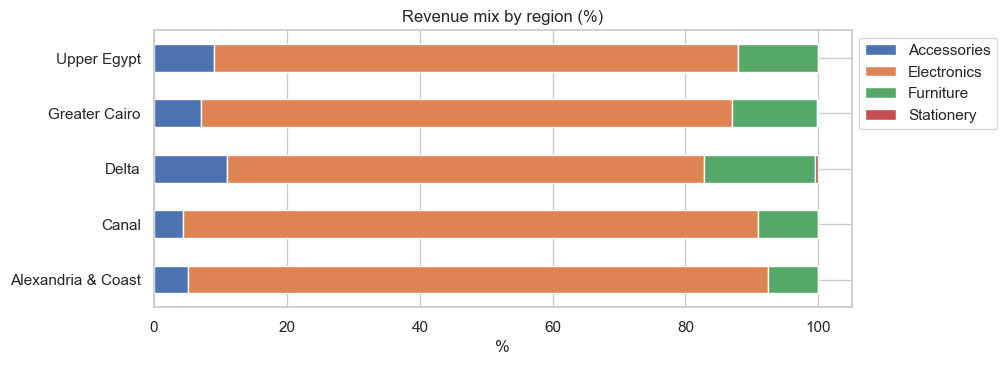

In [18]:
share = done.pivot_table(index="region", columns="category", values="revenue", aggfunc="sum", fill_value=0)
share = share.div(share.sum(axis=1), axis=0)        # each row as % of its region
ax = (share.drop(index="Unknown") * 100).plot(kind="barh", stacked=True, figsize=(9, 3.6))
ax.set(title="Revenue mix by region (%)", xlabel="%", ylabel="")
ax.legend(bbox_to_anchor=(1, 1))
plt.show()

Electronics is the bulk everywhere, from 72% of the revenue in the Delta (which buys more furniture) to 87% in Alexandria & Coast.
Greater Cairo is the biggest region, but its mix is close to the average.

## 4.2 `crosstab`: counts of two categories

In [19]:
pd.crosstab(done["segment"], done["category"])

category,Accessories,Electronics,Furniture,Stationery
segment,,,,
Consumer,235,135,98,85
Corporate,162,103,64,64
Small Business,55,31,22,19
Unknown,1,0,0,0


In [20]:
pd.crosstab(done["segment"], done["category"], normalize="index").round(2)      # each row adds up to 1

category,Accessories,Electronics,Furniture,Stationery
segment,,,,
Consumer,0.42,0.24,0.18,0.15
Corporate,0.41,0.26,0.16,0.16
Small Business,0.43,0.24,0.17,0.15
Unknown,1.00,0.00,0.00,0.00


Consumers, corporates and small businesses buy the same mix of categories (by number of lines).
Corporates differ in *how many* units they buy per line, not *what* they buy.

---
# 5️⃣ `concat`: stack tables

Tables with the same columns, one under the other: monthly exports, yearly files.

In [21]:
y2024 = done[done["order_date"].dt.year == 2024]
y2025 = done[done["order_date"].dt.year == 2025]
both = pd.concat([y2024, y2025], ignore_index=True)       # ignore_index: number the rows 0..n-1 again
print(len(y2024), "+", len(y2025), "=", len(both))

496 + 578 = 1074


`concat` matches columns **by name**. A column that one table doesn't have is filled with NaN:

In [22]:
a = pd.DataFrame({"product": ["Mouse"], "units": [3]})
b = pd.DataFrame({"product": ["Lamp"], "units": [1], "colour": ["black"]})
pd.concat([a, b], ignore_index=True)

,product,units,colour
0,Mouse,3,NaN
1,Lamp,1,black


---
# 6️⃣ `merge`: join tables on a key

`sales.csv` doesn't exist in a real shop. What exists is the raw tables:

In [23]:
orders = pd.read_csv(DATA / "orders.csv", parse_dates=["order_date"])
customers = pd.read_csv(DATA / "customers.csv")
products = pd.read_csv(DATA / "products.csv")
governorates = pd.read_csv(DATA / "governorates.csv")
for name, t in [("orders", orders), ("customers", customers), ("products", products), ("governorates", governorates)]:
    print(f"{name:13} {t.shape}  {t.columns.tolist()}")

orders        (1501, 8)  ['order_id', 'order_date', 'customer_id', 'product_id', 'quantity', 'unit_price', 'discount', 'status']
customers     (200, 6)  ['customer_id', 'name', 'email', 'governorate', 'segment', 'signup_date']
products      (12, 5)  ['product_id', 'product_name', 'category', 'list_price', 'unit_cost']
governorates  (17, 3)  ['governorate', 'region', 'delivery_fee']


An order knows its `customer_id` and `product_id`, nothing else. The name is in `customers`, the category in `products`.
The shared column is the **key**.

In [24]:
op = orders.merge(products[["product_id", "product_name", "category", "unit_cost"]], on="product_id", how="left")
print(orders.shape, "->", op.shape)
op[["order_id", "product_id", "product_name", "category", "unit_price", "unit_cost"]].head()

(1501, 8) -> (1501, 11)


,order_id,product_id,product_name,category,unit_price,unit_cost
0,10548,110,Lamp,Furniture,712.00,370
1,10985,107,Backpack,Accessories,900.00,420
2,10713,103,Tablet,Electronics,"10,450.00",9000
3,10639,111,Notebook,Stationery,60.00,20
4,10472,111,Notebook,Stationery,60.00,20


Each order found its product: same number of rows, 3 new columns. That's what a good lookup join looks like.

---
# 7️⃣ Join types: which rows survive?

When a key is on one side only, the `how=` argument decides what happens.

In [25]:
orphans = orders[~orders["customer_id"].isin(customers["customer_id"])]
print("orders whose customer isn't in customers.csv:")
print(orphans[["order_id", "customer_id"]].to_string(index=False))
silent = customers[~customers["customer_id"].isin(orders["customer_id"])]
print("customers with no order:", len(silent))

orders whose customer isn't in customers.csv:
 order_id  customer_id
    10501          902
    10901          901
    10011          901
customers with no order: 42


In [26]:
for how in ["inner", "left", "right", "outer"]:
    m = orders.merge(customers, on="customer_id", how=how)
    print(f"{how:6} {len(m):5} rows")

inner   1498 rows
left    1501 rows
right   1540 rows
outer   1543 rows


| `how=` | Keeps | Here |
|---|---|---|
| `inner` | only keys on **both** sides | 1,498: the 3 orphan orders are gone |
| `left` | every row of the **left** table | 1,501: the orphans stay, with NaN for the customer |
| `right` | every row of the **right** table | 1,540: plus the 42 customers who never ordered |
| `outer` | everything | 1,543: orphans and silent customers |

`indicator=True` adds a `_merge` column that says where each row came from:

In [27]:
m = orders.merge(customers, on="customer_id", how="outer", indicator=True)
m["_merge"].value_counts()

_merge
both          1498
right_only      42
left_only        3
Name: count, dtype: int64

`left` is the usual choice for adding information to a table: you keep all your orders, and see which ones didn't find a match.
An `inner` join would have dropped 3 orders without a word.

## 7.1 What was never sold?

A left join from the other side, then keep the rows with no match:

In [28]:
pm = products.merge(orders[["product_id", "order_id"]], on="product_id", how="left", indicator=True)
pm.loc[pm["_merge"] == "left_only", ["product_id", "product_name", "list_price"]]

,product_id,product_name,list_price
1501,112,Pen Set,150


---
# 8️⃣ Merge traps

## 8.1 Keys that don't match exactly

The governorate names in `customers.csv` came from a sign-up form:

In [29]:
cg = customers.merge(governorates, on="governorate", how="left")
print("customers with no region:", cg["region"].isna().sum())
cg.loc[cg["region"].isna(), ["customer_id", "governorate"]].assign(shown=lambda x: "'" + x["governorate"] + "'")

customers with no region: 3


,customer_id,governorate,shown
3,4,cairo,'cairo'
15,16,GIZA,'GIZA '
40,41,alexandria,' alexandria'


`"cairo"`, `"GIZA "` and `" alexandria"` are not `"Cairo"`, `"Giza"`, `"Alexandria"`: a key must match **character for character**.
Clean the keys first:

In [30]:
customers["governorate"] = customers["governorate"].str.strip().str.title()
customers["name"] = customers["name"].str.strip().str.title()
print("after cleaning:", customers.merge(governorates, on="governorate", how="left")["region"].isna().sum(), "without a region")

after cleaning: 0 without a region


## 8.2 ⚠️ Keys that repeat: the row explosion

Join on a key that isn't unique on the "lookup" side and every match becomes a row.
Here's a mistake that looks reasonable: adding the segment by the customer's **name** instead of the id.

In [31]:
oc = orders.merge(customers[["customer_id", "name"]], on="customer_id")
print("unique names:", customers["name"].nunique(), "for", len(customers), "customers")

wrong = oc.merge(customers[["name", "segment"]], on="name")
print(len(oc), "rows ->", len(wrong), "rows")

unique names: 130 for 200 customers
1498 rows -> 2824 rows


No error, no warning. 1,498 orders became 2,824 rows, and every sum on the result is now wrong:

In [32]:
oc["gross"] = oc["quantity"] * oc["unit_price"]
wrong["gross"] = wrong["quantity"] * wrong["unit_price"]
print(f"real gross:   {oc['gross'].sum():>14,.0f}")
print(f"after merge:  {wrong['gross'].sum():>14,.0f}")

real gross:       45,265,922
after merge:      69,222,600


**The fix: `validate=`.** Tell Pandas what the join *should* be, and it checks:

In [33]:
try:
    oc.merge(customers[["name", "segment"]], on="name", validate="many_to_one")
except pd.errors.MergeError as e:
    print("MergeError:", e)

MergeError: Merge keys are not unique in right dataset; not a many-to-one merge


In [34]:
right = orders.merge(customers[["customer_id", "name", "segment"]], on="customer_id",
                     how="left", validate="many_to_one")
print(len(orders), "->", len(right), "rows: one customer per order, as it should be")

1501 -> 1501 rows: one customer per order, as it should be


| `validate=` | Means |
|---|---|
| `"one_to_one"` | the key is unique on both sides |
| `"many_to_one"` | many rows on the left, one match on the right (the usual lookup) |
| `"one_to_many"` | the other way |

Three checks after every merge: **the row count**, **`indicator=True`** for unmatched keys, and **`validate=`**.

## 8.3 Building `sales` from the raw tables

The whole recipe (the cleaning steps come in the next lesson):

In [35]:
s = (orders
     .merge(customers[["customer_id", "name", "governorate", "segment"]], on="customer_id", how="left", validate="many_to_one")
     .merge(governorates[["governorate", "region"]], on="governorate", how="left", validate="many_to_one")
     .merge(products[["product_id", "product_name", "category", "unit_cost"]], on="product_id", how="left", validate="many_to_one"))
print(orders.shape, "->", s.shape)
s[["order_id", "name", "region", "product_name", "category", "status"]].head()

(1501, 8) -> (1501, 15)


,order_id,name,region,product_name,category,status
0,10548,Salma Fawzy,Canal,Lamp,Furniture,returned
1,10985,Laila Abdelrahman,Delta,Backpack,Accessories,completed
2,10713,Hana Mostafa,Greater Cairo,Tablet,Electronics,completed
3,10639,Laila Abdelrahman,Delta,Notebook,Stationery,returned
4,10472,Fatma El-Sayed,Greater Cairo,Notebook,Stationery,shipped


1,501 rows in, 1,501 rows out: every merge was a lookup, none of them added or dropped an order.

---
# 🧰 Summary

| Task | Code |
|---|---|
| One number per group | `df.groupby("g")["col"].sum()` |
| Rows per group | `df.groupby("g").size()` |
| Several groups | `groupby(["g1", "g2"])`, then `unstack()` |
| Several numbers, named | `agg(orders=("order_id", "nunique"), revenue=("revenue", "sum"))` |
| Group value on every row | `df.groupby("g")["col"].transform("sum")` |
| Two-way table of a number | `pivot_table(index=, columns=, values=, aggfunc=, fill_value=0, margins=True)` |
| Two-way table of counts | `pd.crosstab(a, b, normalize="index")` |
| Stack tables | `pd.concat([a, b], ignore_index=True)` |
| Join on a key | `a.merge(b, on="key", how="left", validate="many_to_one", indicator=True)` |

* `inner` drops unmatched rows silently; `left` keeps them so you can see them.
* Keys must match character for character: clean them before the merge.
* A repeated key multiplies rows. Check the row count, and use `validate=`.

**Next lesson:** light cleaning: missing values, duplicates, types and simple outliers.

📚 All the lessons of the course: [zero-grad.com/courses/da](https://zero-grad.com/courses/da/)